-------
## Projekt 1 - Wstęp do Uczenia Maszynowego 2026Z

## Kod KM1

-------


**Imię i Nazwisko:** Jakub Gronkiewicz

**Prowadzący:** AK

**Kierunek:** IAD

**Numer albumu:** 338989

------

> Proszę o dostosowanie nazw rozdziałów i podrozdziałów do nazw umieszczonych w raporcie.

### *Import pakietów*

-------

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree
import seaborn as sns

### *1. Eksploracyjna analiza danych*
-------

In [123]:
X_test = pd.read_csv("X_test.csv")
X_train = pd.read_csv("X_train.csv")
y_train = pd.read_csv("y_train.csv")

df = X_train.copy()
df['TARGET'] = y_train.iloc[:, -1]

In [ ]:
print("Wymiar X_train:", X_train.shape)
print("Wymiar y_train:", y_train.shape)


Wymiar X_train: (6400, 23)
Wymiar y_train: (6400, 1)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,TARGET
0,19912.825563,2,2,1,44,2,0,0,2,2.0,2,11836.004209,15921.250919,23094.542467,17974.686955,18841.431580,15783.245882,1423.110120,3049.157007,157.071859,733.154414,478.947062,379.984156,1
1,55043.974658,1,1,2,24,4,4,4,4,3.0,2,35466.806974,32443.064083,36533.557269,38224.238356,39238.101886,40576.008942,2037.243581,1854.121994,300.752767,1020.891555,-455.518882,2469.448131,0
2,20006.277688,2,2,2,31,0,0,0,0,NaN,0,19100.698571,25342.481628,22411.774647,28966.654890,19049.390827,15402.347969,10175.669342,4573.613449,-771.581797,-283.002435,4857.385369,3474.203409,0
3,128698.125632,1,1,2,31,-1,-1,-1,-2,-2.0,-1,30276.574721,46648.057429,-2138.872526,-2834.834778,-786.605171,49261.032919,10858.685707,1101.369070,25.587625,-331.783255,49191.348594,3767.305856,0
4,358711.329669,2,1,1,34,-2,-2,-2,-2,-2.0,-2,737.324220,21980.528398,15059.484302,16441.809554,14173.086443,21134.235164,6945.506312,691.104497,7333.776096,5973.950428,5218.051932,28455.969902,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6395,288678.557616,2,1,1,37,-1,-1,-1,-1,-1.0,-2,2325.830201,7925.121890,-6698.723426,837.345173,-1987.121950,-561.298223,-867.596647,3636.118481,5690.789840,3717.974738,-496.850679,2699.824180,1
6396,9307.905646,1,2,2,23,0,0,0,0,0.0,0,5739.438721,6826.878006,7490.212429,8242.425148,5955.512770,9908.230189,3251.367754,2206.862485,1283.619982,2040.264827,1051.530534,-303.803681,0
6397,34572.722976,2,3,1,36,2,2,2,2,2.0,2,21066.610696,22928.850614,13990.096011,15188.941284,13385.064296,10042.748114,535.055654,925.486104,9.528748,1810.440625,-294.622420,528.263856,1
6398,395011.994416,1,1,2,34,-2,-2,-2,-2,-1.0,0,2019.841427,6167.362505,-7059.859117,2425.279736,14616.972881,10010.042057,-576.357751,581.313341,4389.415795,-2333.612766,3792.747204,7477.137612,0


In [97]:
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 1000)

print(" STATYSTYKI OPISOWE ")
display(X_train.describe().round(2))





t0, t1 = y_train.value_counts()
t_sum = t1 + t0
t0per = t0/t_sum
t1per = t1/t_sum
print(f"rozkład zmiennej docelowej liczbowo i procentowo:\n 0 posiada {t0} wystąpień co stanowi {t0per * 100} procent wszystkich wystąpień \n 1 posiada {t1} wystąpień co stanowi {t1per * 100} procent wszystkich wystąpień\n")



 STATYSTYKI OPISOWE 


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
count,6400.00,6400.00,6400.00,6400.00,6400.00,6400.00,6400.00,6400.00,6400.00,5764.00,6400.00,6400.00,6400.00,6400.00,6400.00,6400.00,5747.00,6400.00,6400.00,6400.00,5765.00,6400.00,6400.00
mean,167058.28,1.60,1.84,1.57,34.83,-0.02,-0.15,-0.17,-0.23,-0.28,-0.31,50468.41,48687.29,46668.66,42570.47,39376.52,38299.32,5915.51,5880.76,5467.80,4885.01,5095.02,5683.63
std,130788.62,0.49,0.80,0.52,9.09,1.13,1.18,1.19,1.16,1.12,1.13,73439.10,71018.89,69070.54,63682.29,59482.26,59008.76,16238.05,18325.75,16933.34,16338.83,16667.88,20156.37
min,-157.51,1.00,0.00,0.00,19.00,-2.00,-2.00,-3.00,-2.00,-2.00,-2.00,-30480.00,-42319.73,-31630.64,-55474.96,-35278.29,-233709.69,-6738.56,-10167.64,-7045.83,-7348.72,-5067.45,-6447.08
25%,54027.84,1.00,1.00,1.00,28.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,5918.96,5251.58,4985.88,4228.75,3888.38,3240.55,831.05,590.11,471.69,316.22,363.16,315.56
50%,138508.70,2.00,2.00,2.00,33.00,0.00,0.00,0.00,0.00,0.00,0.00,22774.25,21970.02,21111.90,19429.49,17977.09,17057.20,2488.56,2435.12,1963.01,1690.26,1768.45,1765.10
75%,236847.70,2.00,2.00,2.00,41.00,0.00,0.00,0.00,0.00,0.00,0.00,66809.80,63246.89,59476.04,53533.84,49679.87,48644.16,5589.82,5579.01,4841.17,4331.01,4436.39,4500.50
max,783258.37,2.00,6.00,3.00,73.00,8.00,7.00,7.00,7.00,7.00,8.00,623073.93,559334.62,548472.31,536004.79,502351.97,496311.17,306664.79,579958.41,402667.94,432461.89,328741.93,527618.45


rozkład zmiennej docelowej liczbowo i procentowo:
 0 posiada 5019 wystąpień co stanowi 78.421875 procent wszystkich wystąpień 
 1 posiada 1381 wystąpień co stanowi 21.578125 procent wszystkich wystąpień



C:\Users\Medion\AppData\Local\Temp\ipykernel_9252\3490226017.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, x=col, ax=ax, palette='pastel')
C:\Users\Medion\AppData\Local\Temp\ipykernel_9252\3490226017.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, x=col, ax=ax, palette='pastel')
C:\Users\Medion\AppData\Local\Temp\ipykernel_9252\3490226017.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, x=col, ax=ax, palette='pastel')
C:\Users\Medion\AppData\Local\Temp\ipykernel_9252\3490226017.py:

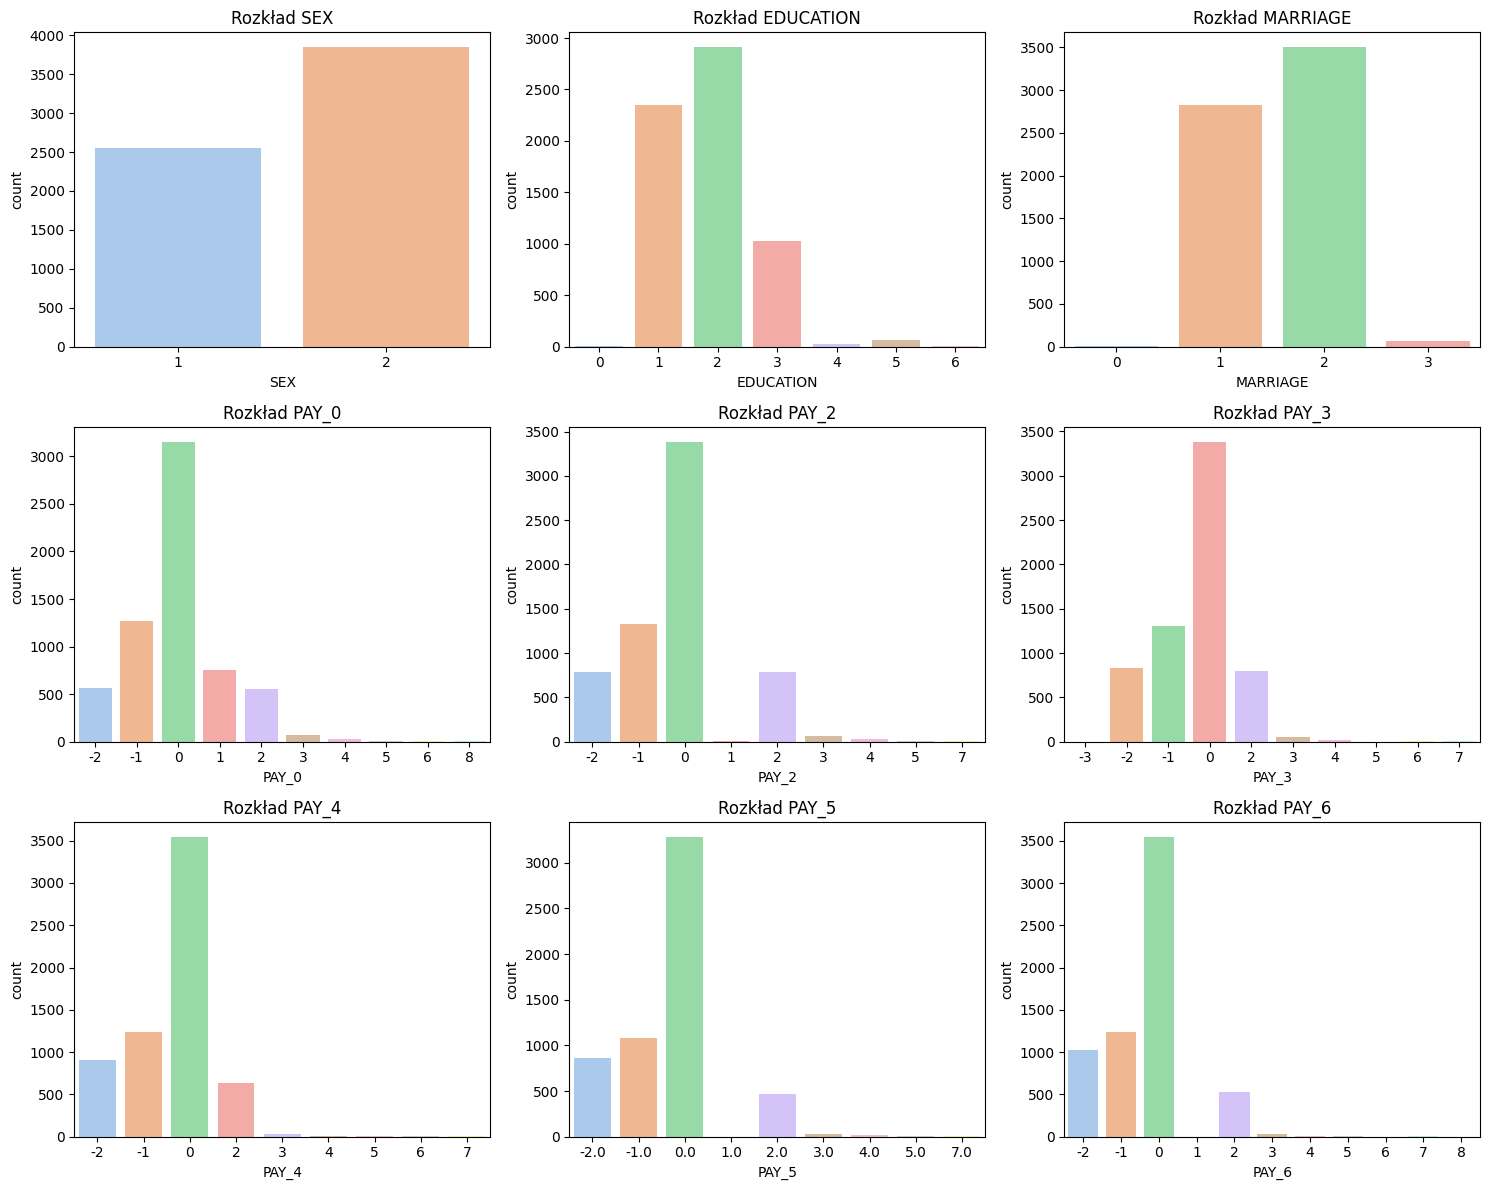

In [102]:
cat_cols = ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.flatten(), cat_cols):
    sns.countplot(data=X_train, x=col, ax=ax, palette='pastel')
    ax.set_title(f'Rozkład {col}')
plt.tight_layout()
plt.show()

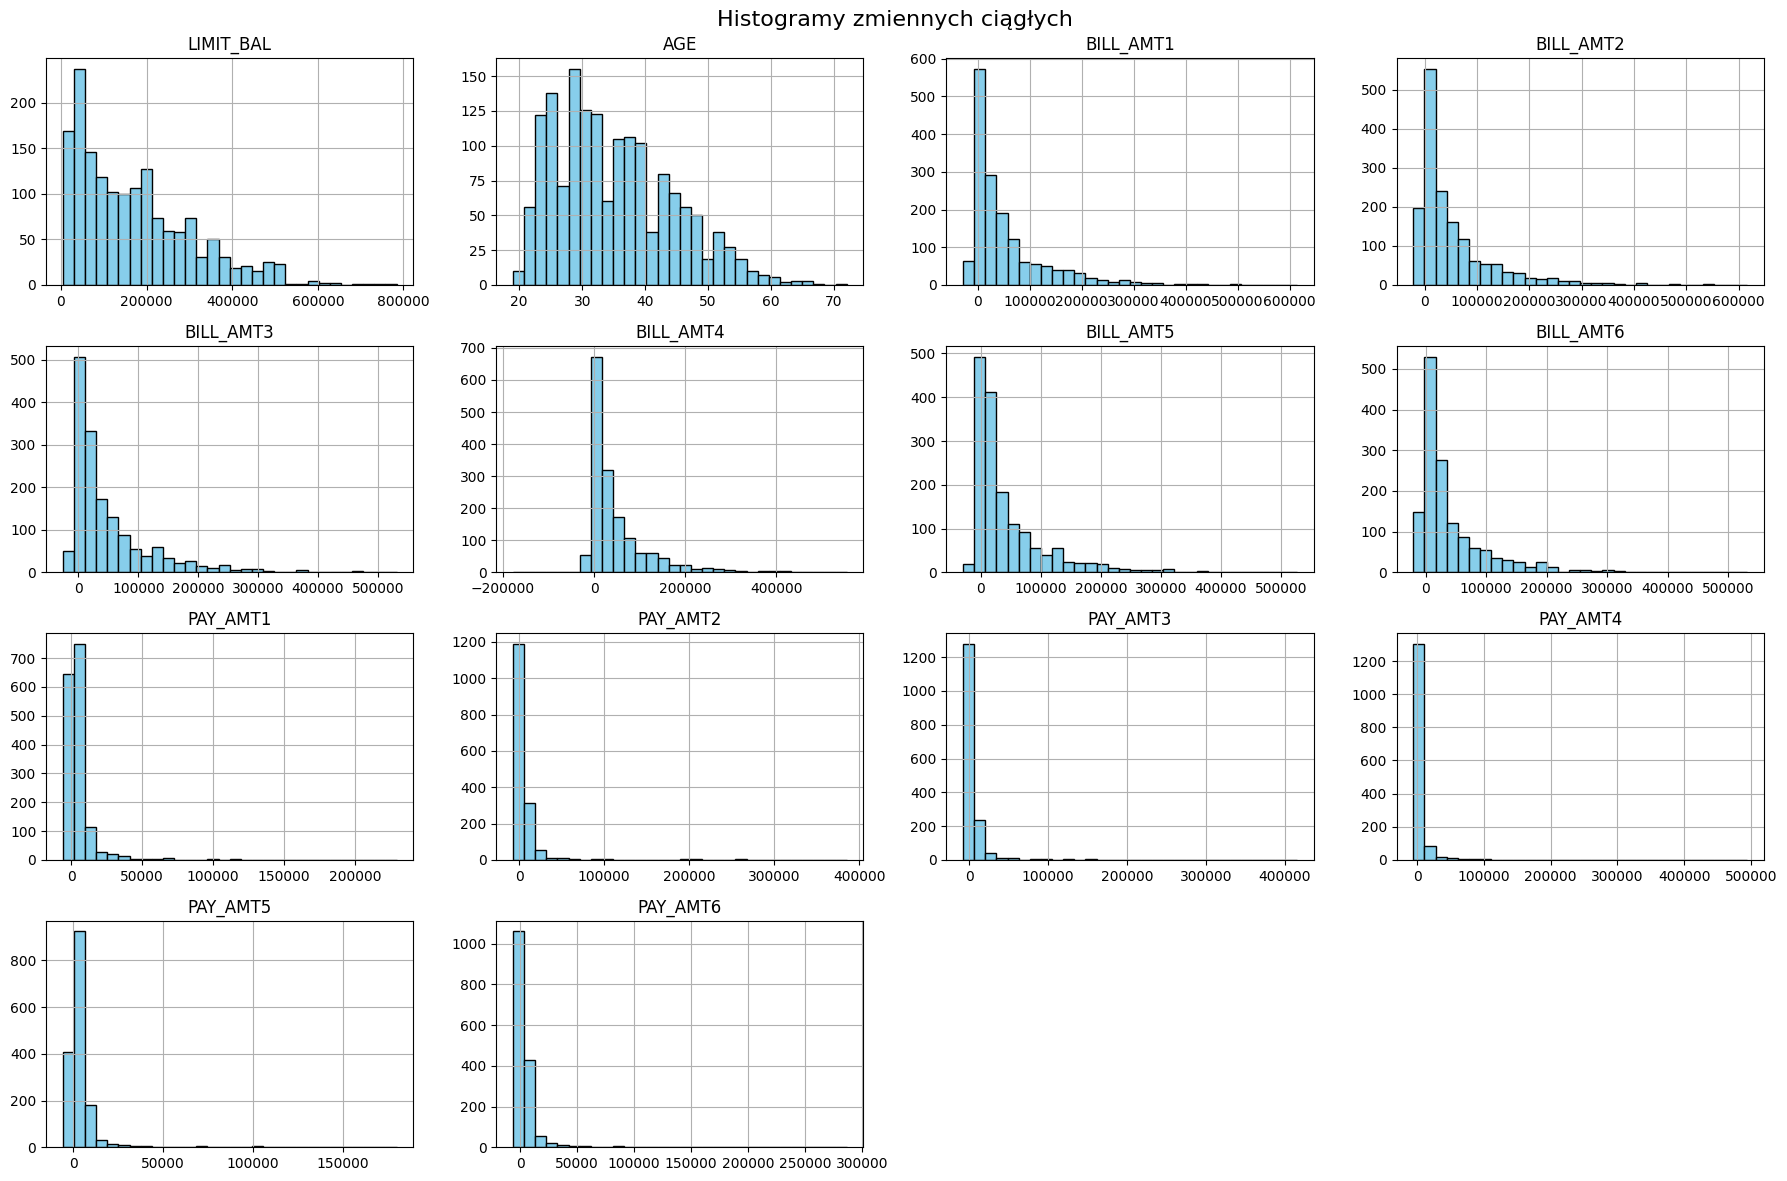

In [ ]:

num_cols = ['LIMIT_BAL', 'AGE'] + [f'BILL_AMT{i}' for i in range(1, 7)] + [f'PAY_AMT{i}' for i in range(1, 7)]


X_train[num_cols].hist(bins=30, figsize=(18, 12), color='skyblue', edgecolor='black')
plt.suptitle('Histogramy zmiennych ciągłych', fontsize=16)
plt.tight_layout()
plt.show()

In [110]:
print("JAWNE BRAKI DANYCH")
missing_count = X_train.isna().sum()
missing_percent = (X_train.isna().mean() * 100).round(2)

missing_df = pd.DataFrame({'Liczba braków': missing_count, 'Procent (%)': missing_percent})
display(missing_df[missing_df['Liczba braków'] > 0])

JAWNE BRAKI DANYCH


,Liczba braków,Procent (%)
PAY_5,636,9.94
BILL_AMT6,653,10.20
PAY_AMT4,635,9.92


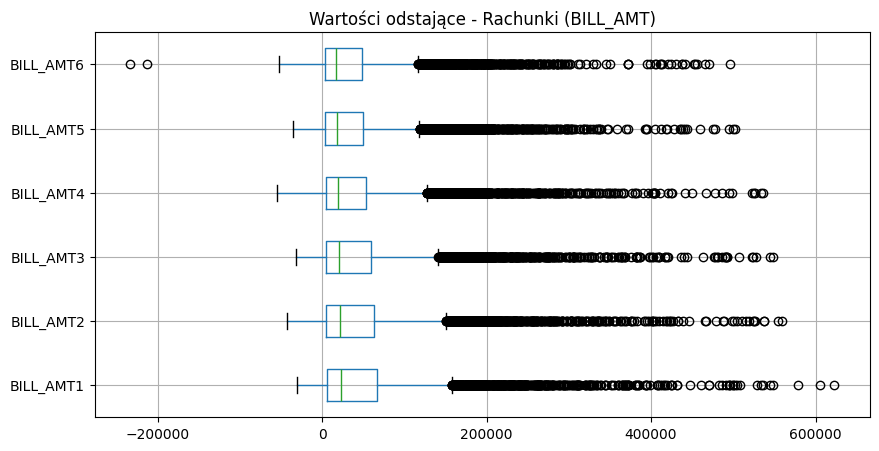

In [118]:
plt.figure(figsize=(10, 5))
X_train[[c for c in X_train.columns if c.startswith('BILL_AMT')]].boxplot(vert=False)
plt.title('Wartości odstające - Rachunki (BILL_AMT)')
plt.show()

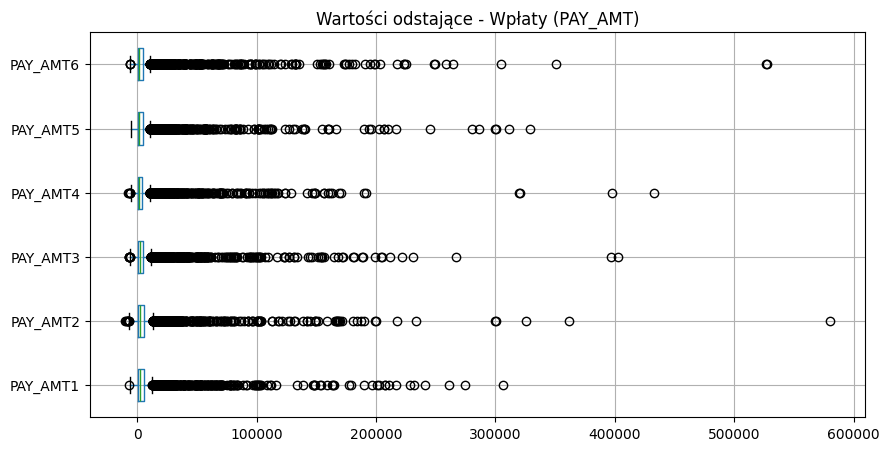

In [119]:
plt.figure(figsize=(10, 5))
X_train[[c for c in X_train.columns if c.startswith('PAY_AMT')]].boxplot(vert=False)
plt.title('Wartości odstające - Wpłaty (PAY_AMT)')
plt.show()

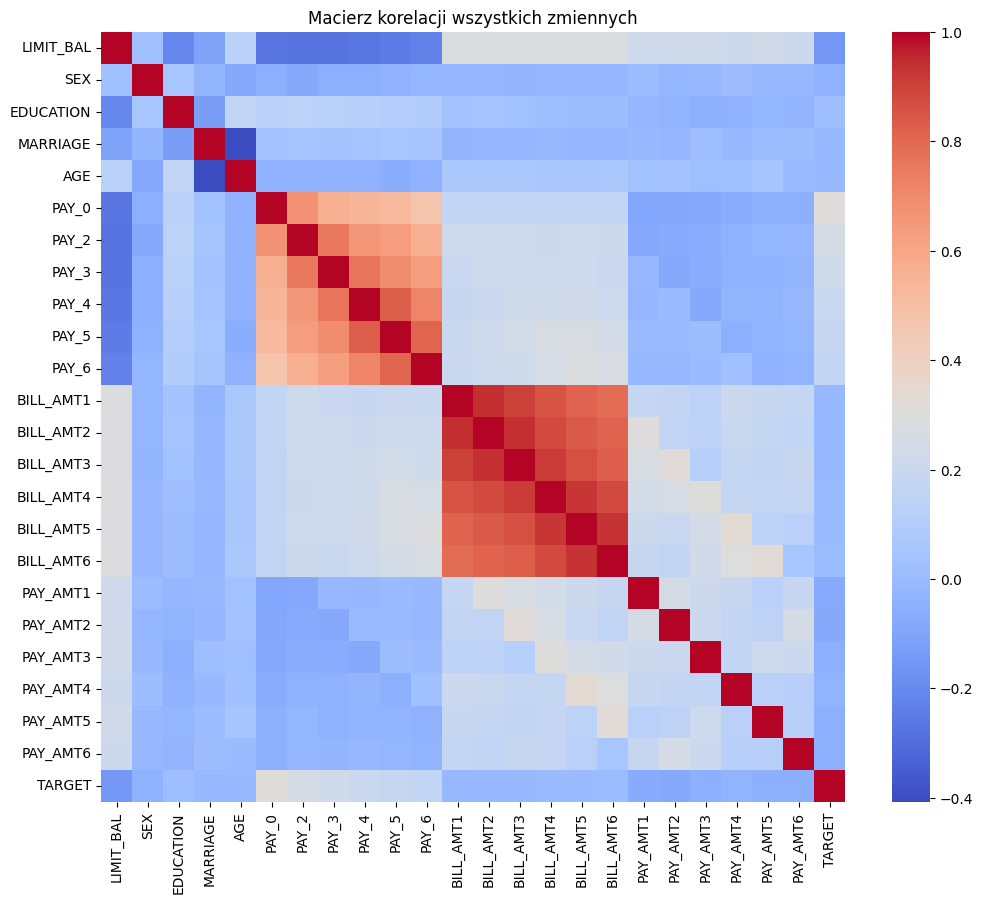

In [129]:
plt.figure(figsize=(12, 10))
corr = df.corr(numeric_only=True)

sns.heatmap(corr, cmap='coolwarm', annot=False)
plt.title('Macierz korelacji wszystkich zmiennych')
plt.show()

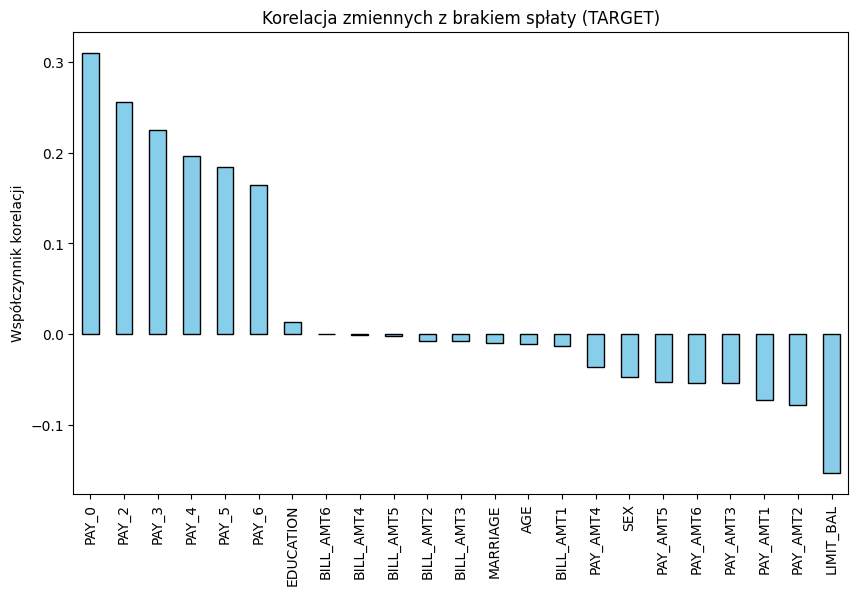

In [130]:
plt.figure(figsize=(10, 6))

target_corr = corr['TARGET'].sort_values(ascending=False).drop('TARGET')

target_corr.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Korelacja zmiennych z brakiem spłaty (TARGET)')
plt.ylabel('Współczynnik korelacji')
plt.show()

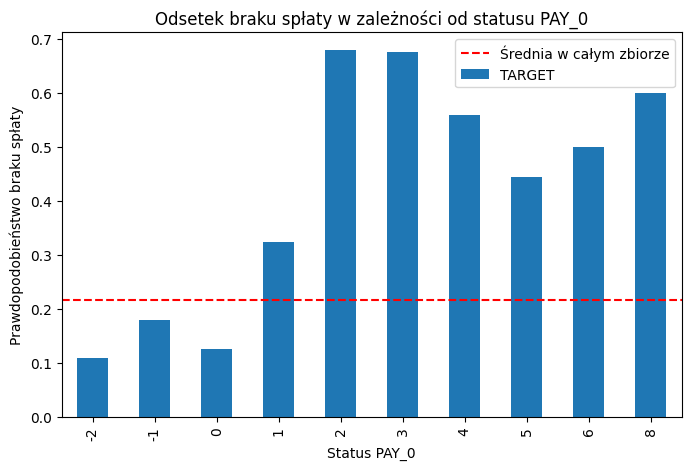

In [132]:
plt.figure(figsize=(8, 5))
df.groupby('PAY_0')['TARGET'].mean().plot(kind='bar')

plt.title('Odsetek braku spłaty w zależności od statusu PAY_0')
plt.xlabel('Status PAY_0')
plt.ylabel('Prawdopodobieństwo braku spłaty')
plt.axhline(df['TARGET'].mean(), color='red', linestyle='--', label='Średnia w całym zbiorze')
plt.legend()
plt.show()

### *1.1 Podrozdział 1 (edit)*
-------

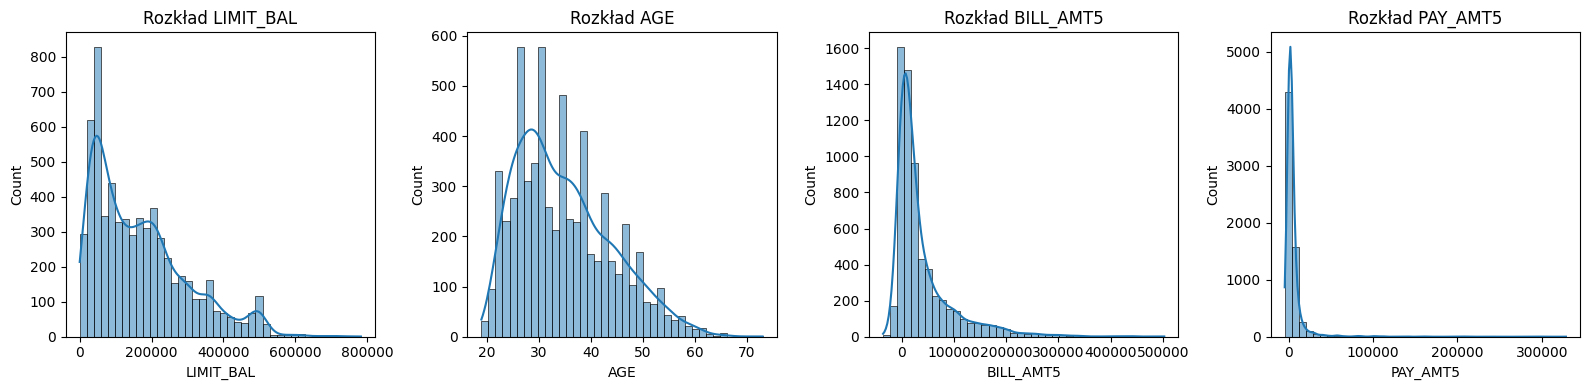

In [111]:
num_cols = ["LIMIT_BAL", "AGE", "BILL_AMT5", "PAY_AMT5"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i in range(len(num_cols)):
    nazwa_kolumny = num_cols[i]
    sns.histplot(df_EDA[nazwa_kolumny], bins=40, kde=True, ax=axes[i])
    axes[i].set_title("Rozkład " + nazwa_kolumny)

plt.tight_layout()
plt.show()

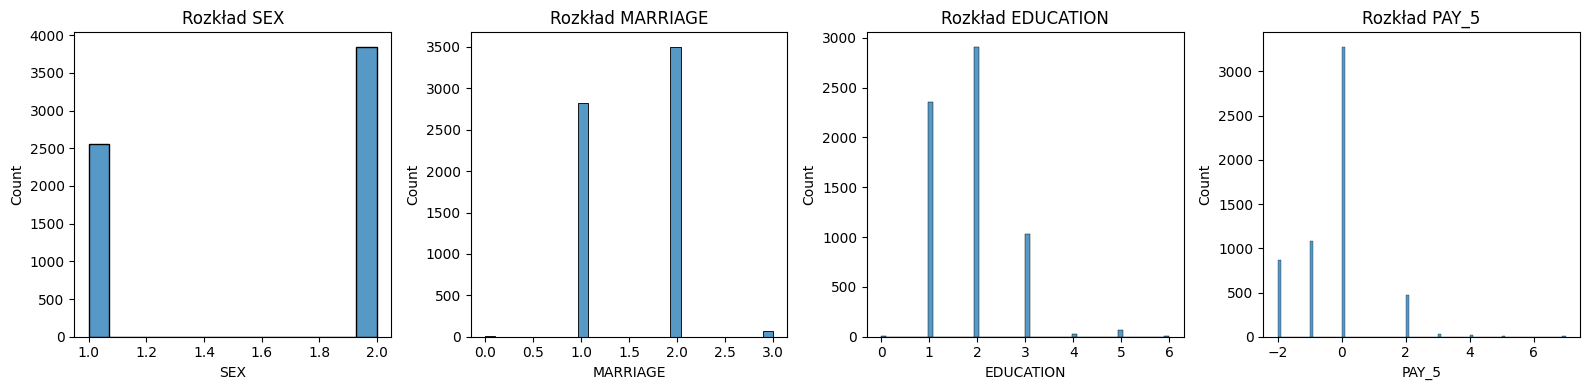

In [104]:
num_cols = ["SEX", "MARRIAGE", "EDUCATION", "PAY_5"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i in range(len(num_cols)):
    nazwa_kolumny = num_cols[i]
    sns.histplot(df_EDA[nazwa_kolumny], ax=axes[i])
    axes[i].set_title("Rozkład " + nazwa_kolumny)

plt.tight_layout()
plt.show()

In [67]:
# 1. Sprawdzenie jawnych braków danych (NaN)
print("Kolumny z jawnymi brakami danych (NaN):")
wszystkie_kolumny = X_train.columns
ilosc_wierszy = len(X_train)

# pętla sprawdzająca każdą kolumnę po kolei
for i in range(len(wszystkie_kolumny)):
    nazwa_kol = wszystkie_kolumny[i]
    braki = X_train[nazwa_kol].isna().sum()
    
    # wypisz tylko jeśli są jakieś braki
    if braki > 0:
        procent = (braki / ilosc_wierszy) * 100
        procent_zaokr = round(procent, 2)
        print(f"Kolumna: {str(nazwa_kol)} | Liczba NaN: {str(braki)} | Procent (%):  {str(procent_zaokr)}")


# 2. Sprawdzenie ukrytych braków i rzadkich kategorii w zmiennych kategorycznych


Kolumny z jawnymi brakami danych (NaN):
Kolumna: PAY_5 | Liczba NaN: 636 | Procent (%):  9.94
Kolumna: BILL_AMT6 | Liczba NaN: 653 | Procent (%):  10.2
Kolumna: PAY_AMT4 | Liczba NaN: 635 | Procent (%):  9.92


In [79]:
kategorie = ["SEX", "EDUCATION", "MARRIAGE"]

for i in range(len(kategorie)):
    nazwa = kategorie[i]
    
    if nazwa in X_train.columns:
        print("\nLiczebność kategorii dla " + nazwa + ":")
        
        # rozbicie na osobne zmienne, żeby było "jaśniej"
        zliczone = X_train[nazwa].value_counts(dropna=False)
        posortowane = zliczone.sort_index()
        print(posortowane)


Liczebność kategorii dla SEX:
SEX
1    2555
2    3845
Name: count, dtype: int64

Liczebność kategorii dla EDUCATION:
EDUCATION
0       4
1    2352
2    2910
3    1030
4      29
5      69
6       6
Name: count, dtype: int64

Liczebność kategorii dla MARRIAGE:
MARRIAGE
0      11
1    2824
2    3501
3      64
Name: count, dtype: int64


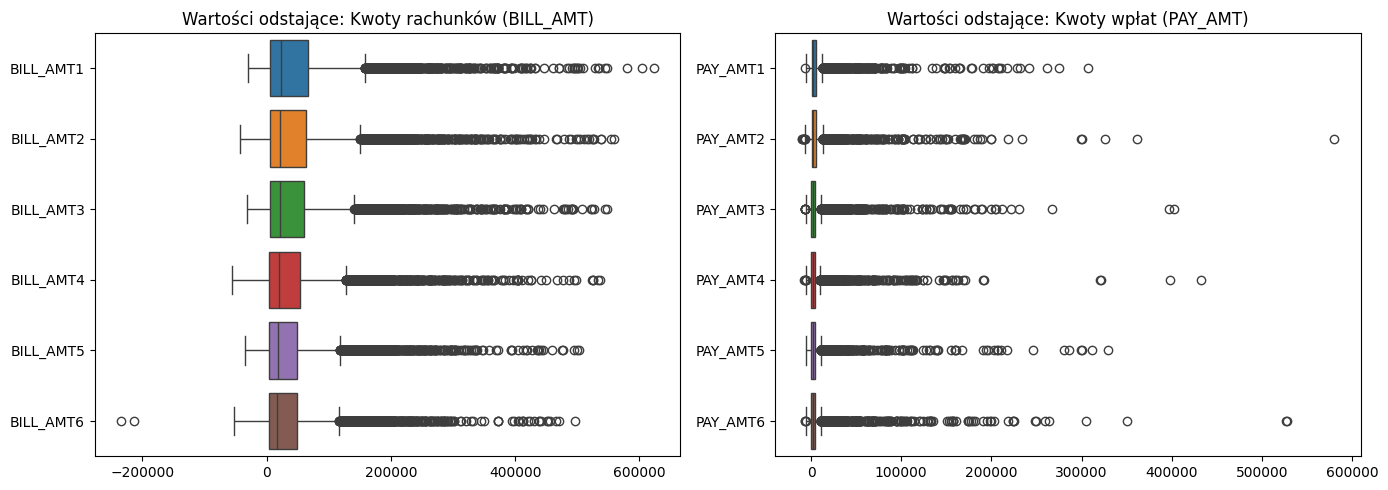

Liczba klientów z ujemnym rachunkiem (nadpłatą) w co najmniej 1 miesiącu: 2429
Liczba klientów z rachunkiem BILL_AMT1 przekraczającym LIMIT_BAL: 626


In [72]:
bill_cols = [c for c in X_train.columns if c.startswith("BILL_AMT")]
pay_amt_cols = [c for c in X_train.columns if c.startswith("PAY_AMT")]

# 1. Wykresy pudełkowe (boxploty) dla wyciągów i wpłat
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=X_train[bill_cols], ax=axes[0], orient="h")
axes[0].set_title("Wartości odstające: Kwoty rachunków (BILL_AMT)")

sns.boxplot(data=X_train[pay_amt_cols], ax=axes[1], orient="h")
axes[1].set_title("Wartości odstające: Kwoty wpłat (PAY_AMT)")
plt.tight_layout()
plt.show()

# 2. Sprawdzenie specyficznych anomalii finansowych
neg_bills = (X_train[bill_cols] < 0).any(axis=1).sum()
over_limit = (X_train["BILL_AMT1"] > X_train["LIMIT_BAL"]).sum()
print(f"Liczba klientów z ujemnym rachunkiem (nadpłatą) w co najmniej 1 miesiącu: {neg_bills}")
print(f"Liczba klientów z rachunkiem BILL_AMT1 przekraczającym LIMIT_BAL: {over_limit}")

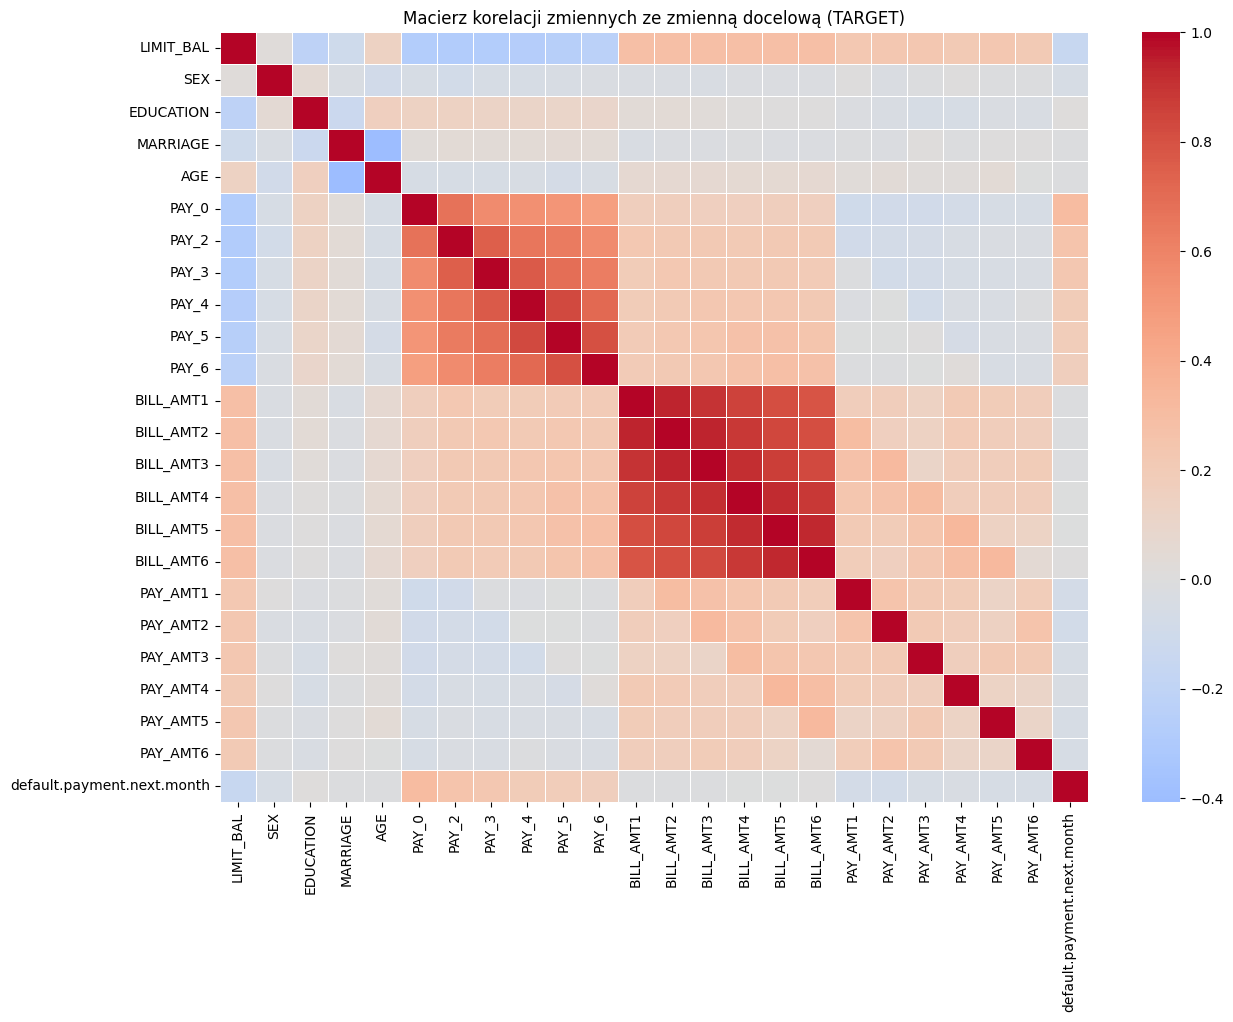

Korelacja zmiennych z TARGET:
default.payment.next.month    1.000
PAY_0                         0.311
PAY_2                         0.256
PAY_3                         0.226
PAY_4                         0.197
PAY_5                         0.185
PAY_6                         0.165
EDUCATION                     0.014
BILL_AMT6                     0.000
BILL_AMT4                    -0.001
BILL_AMT5                    -0.002
BILL_AMT2                    -0.008
BILL_AMT3                    -0.008
MARRIAGE                     -0.010
AGE                          -0.011
BILL_AMT1                    -0.013
PAY_AMT4                     -0.037
SEX                          -0.047
PAY_AMT5                     -0.053
PAY_AMT6                     -0.054
PAY_AMT3                     -0.054
PAY_AMT1                     -0.073
PAY_AMT2                     -0.078
LIMIT_BAL                    -0.153
Name: default.payment.next.month, dtype: float64


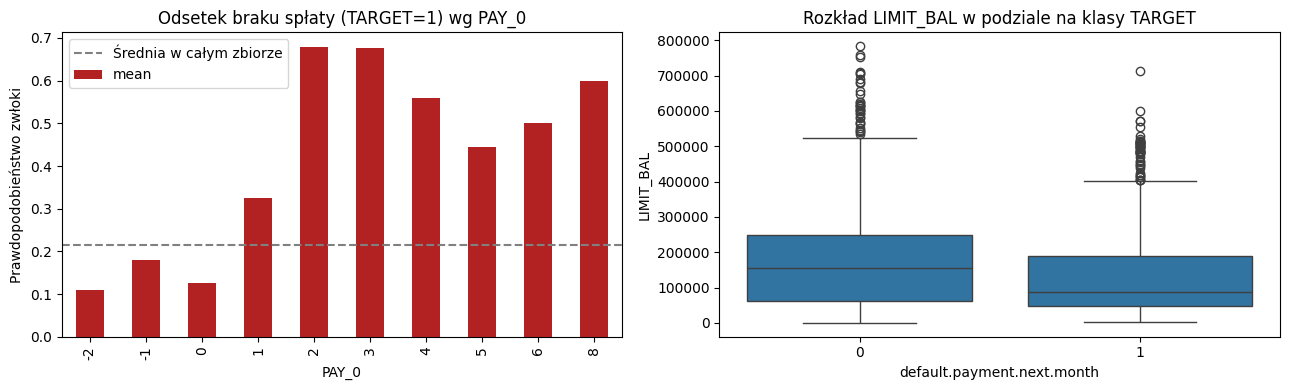

In [78]:
# 1. Mapa ciepła korelacji
plt.figure(figsize=(14, 10))
corr_matrix = df_EDA.corr(numeric_only=True)
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=False, linewidths=0.5)
plt.title("Macierz korelacji zmiennych ze zmienną docelową (TARGET)")
plt.show()

# Wypisanie zmiennych najsilniej skorelowanych z TARGET
print("Korelacja zmiennych z TARGET:")
print(corr_matrix["default.payment.next.month"].sort_values(ascending=False).round(3))

# 2. Wizualizacja relacji kluczowej zmiennej PAY_0 ze zmienną docelową
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Odsetek niespłacających (średnia z TARGET) dla każdej wartości PAY_0
default_by_pay0 = df_EDA.groupby("PAY_0")["default.payment.next.month"].agg(["count", "mean"])
default_by_pay0["mean"].plot(kind="bar", ax=axes[0], color="firebrick")
axes[0].set_title("Odsetek braku spłaty (TARGET=1) wg PAY_0")
axes[0].set_ylabel("Prawdopodobieństwo zwłoki")
axes[0].axhline(df_EDA["default.payment.next.month"].mean(), color="gray", linestyle="--", label="Średnia w całym zbiorze")
axes[0].legend()

# Porównanie rozkładu LIMIT_BAL względem TARGET
sns.boxplot(data=df_EDA, x="default.payment.next.month", y="LIMIT_BAL", ax=axes[1])
axes[1].set_title("Rozkład LIMIT_BAL w podziale na klasy TARGET")
plt.tight_layout()
plt.show()

### *2. Metryka ewaluacji i podział danych*
-------

<bound method NDFrame.head of           LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  \
0     307385.600862    2          1         2   31     -2     -2     -2   
1      52798.031425    1          3         2   55     -1     -1     -1   
2     129447.584602    1          1         2   54      1     -2     -1   
3     104511.880936    2          3         1   25      0      0      0   
4      46126.486961    1          2         2   23      0      0      0   
...             ...  ...        ...       ...  ...    ...    ...    ...   
1595  363073.463090    2          1         2   26     -2     -1     -1   
1596  343962.376717    1          2         1   46     -2     -2     -1   
1597   25083.374398    1          2         2   29      6      5      4   
1598   45103.475988    1          2         2   26      1      2      0   
1599  436679.471863    2          1         1   41     -1     -1     -1   

      PAY_4  PAY_5  ...      BILL_AMT3      BILL_AMT4      BILL_AMT5 

### *2.1 Podrozdział 2 (edit)*
-------

### *3. Podsumowanie i wnioski*
-------